# Student Social Media & Mental Health Impact

**Objective:** Predict `Mental_Health_Score` using student demographics, academic information,
social-media usage, lifestyle variables, and stress level.

### Project workflow

1. Import libraries
2. Load and understand the dataset
3. Data quality checks
4. Exploratory Data Analysis (EDA)
5. Outlier analysis
6. Data cleaning
7. Feature engineering
8. Train/test split
9. Build preprocessing pipelines
10. Train Linear Regression baseline
11. Train Random Forest Regressor
12. Hyperparameter tuning with `RandomizedSearchCV`
13. Evaluate the tuned model
14. Save the `rf_pipeline` model for deployment

> **Model choice:** Random Forest Regressor is retained as the final model workflow from the original notebook.
> The final serialized object is intentionally `rf_pipeline`, as requested.

## 1. Import Libraries

In [ ]:
import  numpy as np
import  pandas as pd
import  matplotlib.pyplot as plt
import  seaborn as sns
from    pathlib                 import Path
from    sklearn.pipeline        import Pipeline
from    sklearn.compose         import ColumnTransformer
from    sklearn.preprocessing   import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from    sklearn.model_selection import train_test_split, RandomizedSearchCV
from    sklearn.linear_model    import LinearRegression
from    sklearn.ensemble        import RandomForestRegressor
from    sklearn.metrics         import r2_score, mean_absolute_error

In [82]:
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load Dataset

In [83]:
DATA_PATH = Path("../data/Student Social Media And Mental Health Impact.csv")

df = pd.read_csv(DATA_PATH)

print(f"Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Dataset loaded successfully.
Rows: 5,000
Columns: 13


In [84]:
df.head(5)

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


## 3. Understand the Dataset

In [85]:
df.shape

(5000, 13)

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [87]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [88]:
df.describe(include="object").T

,count,unique,top,freq
Gender,5000,2,Male,2635
Country,5000,111,Other,1880
Academic_Level,5000,3,Undergraduate,3632
Most_Used_Platform,5000,12,Instagram,1130
Purpose_Of_Use,5000,4,Entertainment,2552
Stress_Level,5000,4,Very High,1621


## 4. Data Quality Checks

In [89]:
missing_values = df.isnull().sum().sort_values(ascending=False)
missing_values

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [90]:
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")

Duplicate rows: 2


In [91]:
df.isnull().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [92]:
df.duplicated().sum()

np.int64(2)

In [117]:
numeric_columns = df.select_dtypes(include="number").columns

Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = ((df[numeric_columns] < lower_bound) | (df[numeric_columns] > upper_bound))

outlier_summary = outliers.sum().sort_values(ascending=False)
outlier_summary

Physical_Activity_Hours    12
Study_Hours                 2
Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64

## 5. Exploratory Data Analysis

### Target distribution — Mental Health Score

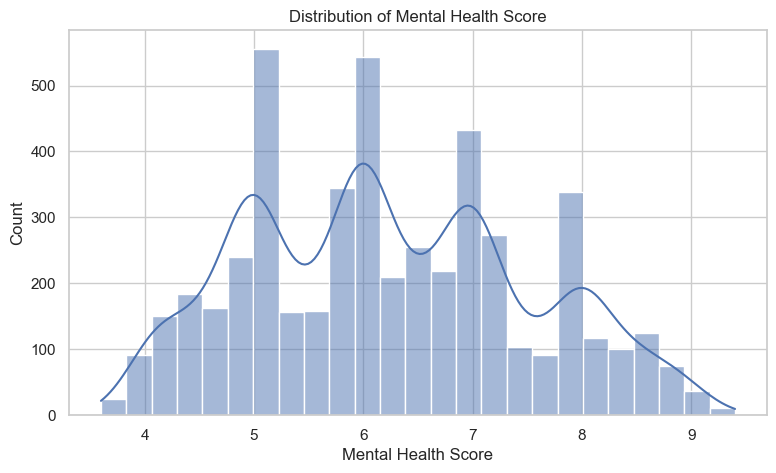

In [93]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="Mental_Health_Score", kde=True)
plt.title("Distribution of Mental Health Score")
plt.xlabel("Mental Health Score")
plt.ylabel("Count")
plt.show()

### Most-used social media platforms

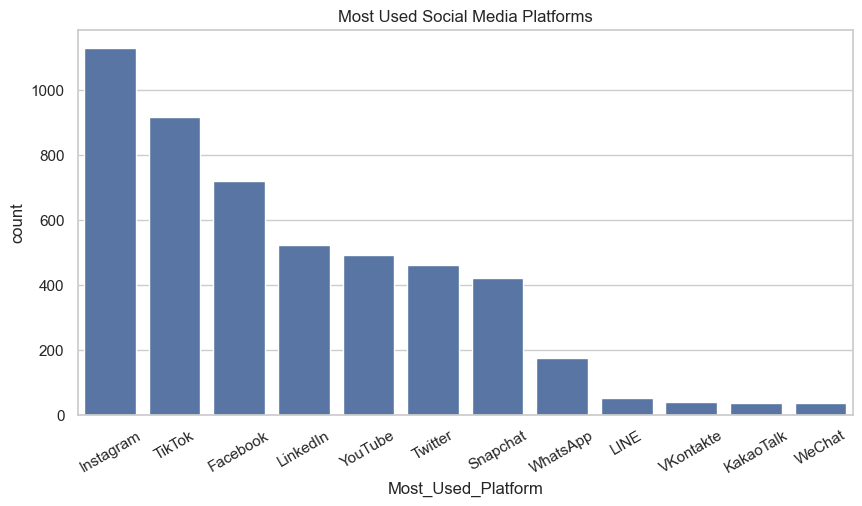

In [94]:
platform_order = df["Most_Used_Platform"].value_counts().index

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="Most_Used_Platform",
    order=platform_order
)
plt.title("Most Used Social Media Platforms")
plt.xticks(rotation=30)
plt.show()

### Mental Health Score by Stress Level

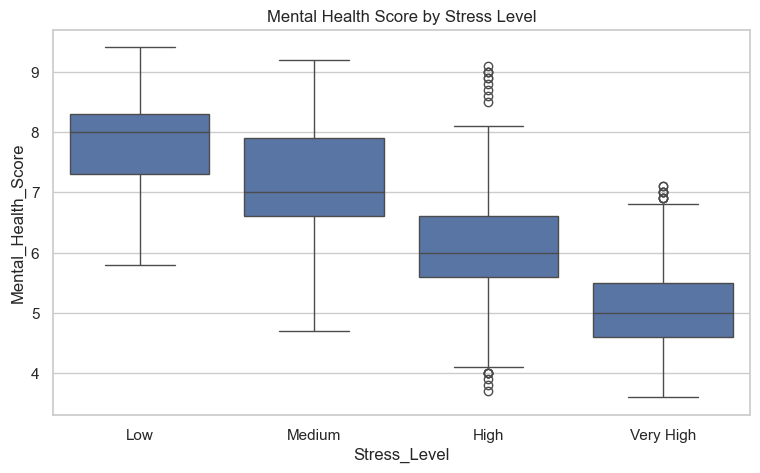

In [95]:
stress_order = ["Low", "Medium", "High", "Very High"]

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="Stress_Level",
    y="Mental_Health_Score",
    order=stress_order
)
plt.title("Mental Health Score by Stress Level")
plt.show()

### Social-media usage vs Mental Health Score

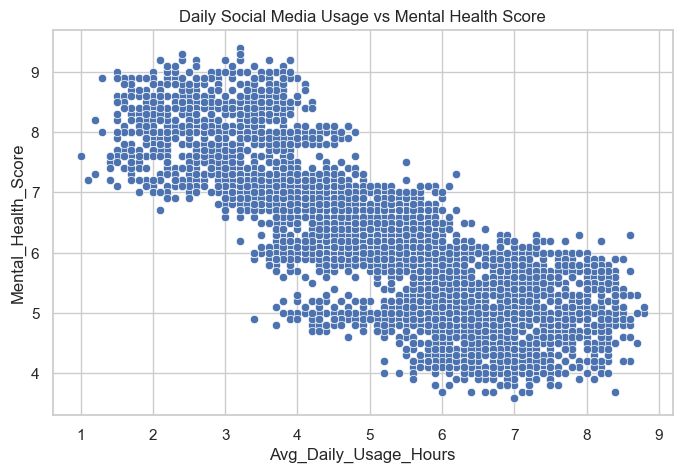

In [96]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Avg_Daily_Usage_Hours",
    y="Mental_Health_Score"
)
plt.title("Daily Social Media Usage vs Mental Health Score")
plt.show()

### Sleep vs Mental Health Score

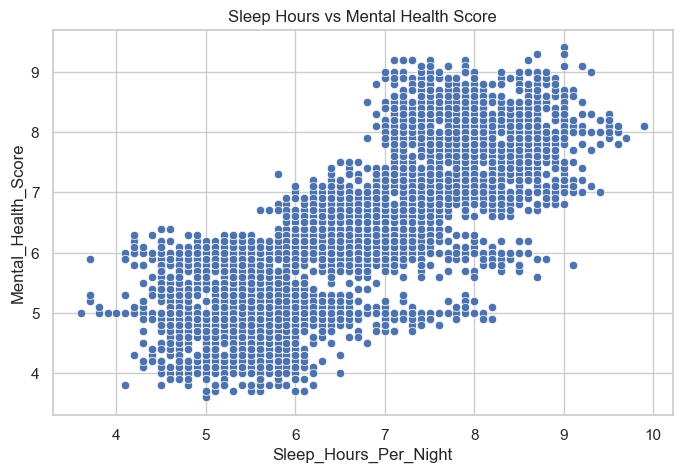

In [97]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Sleep_Hours_Per_Night",
    y="Mental_Health_Score"
)
plt.title("Sleep Hours vs Mental Health Score")
plt.show()

### Correlation heatmap

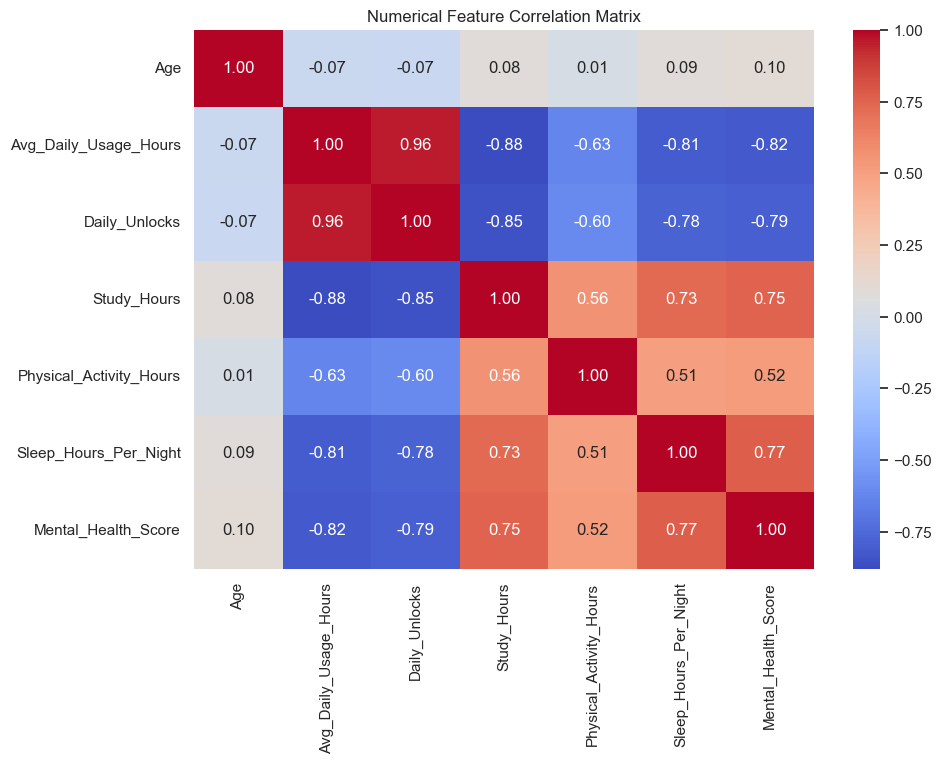

In [98]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)
plt.title("Numerical Feature Correlation Matrix")
plt.show()

## 6. Data Cleaning

In [102]:
# Remove duplicate rows identified during the quality checks.
df.drop_duplicates(inplace=True)

# Physical activity cannot logically be negative.
df["Physical_Activity_Hours"] = df["Physical_Activity_Hours"].clip(lower=0)
print(f"Shape after cleaning: {df.shape}")

Shape after cleaning: (4998, 13)


## 7. Feature Engineering — Country Grouping

In [103]:
# Keep the 10 most frequent countries as individual categories.
# All remaining countries are grouped into "Other".
top_countries = df["Country"].value_counts().index[:10].tolist()

def group_countries(country):
    return country if country in top_countries else "Other"

df["Group_Country"] = df["Country"].apply(group_countries)

print("Top countries:")
print(top_countries)

Top countries:
['Other', 'India', 'USA', 'Canada', 'Australia', 'UK', 'Germany', 'Turkey', 'Mexico', 'France']


In [104]:
df['Group_Country'].value_counts()

Group_Country
Other        3231
India         389
USA           354
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Name: count, dtype: int64

### Why group countries?

`Country` may contain many categories with relatively small frequencies.
Grouping less frequent countries into `Other` reduces unnecessary categorical
complexity while preserving the most common country groups.

In [105]:
num_col = df.select_dtypes(include="number")
num_col.skew()

Age                        0.155008
Avg_Daily_Usage_Hours      0.005575
Daily_Unlocks              0.002309
Study_Hours                0.436125
Physical_Activity_Hours    0.053288
Sleep_Hours_Per_Night      0.123919
Mental_Health_Score        0.207086
dtype: float64

## 8. Feature Selection

In [106]:
skwed_col = ['Study_Hours']
other_numeric_cols = ['Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
                      'Physical_Activity_Hours', 'Sleep_Hours_Per_Night']
ordinal_col = ['Stress_Level']
normal_cols =  ['Gender', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use', 'Group_Country']

feature_cols = skwed_col + other_numeric_cols + ordinal_col + normal_cols

X = df[feature_cols]
y = df['Mental_Health_Score']

print("Features:")
print(feature_cols)
print("\nTarget:")
print(y.name)

Features:
['Study_Hours', 'Age', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night', 'Stress_Level', 'Gender', 'Academic_Level', 'Most_Used_Platform', 'Purpose_Of_Use', 'Group_Country']

Target:
Mental_Health_Score


## 9. Train/Test Split

In [108]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (3498, 12)
Testing set : (1500, 12)


## 10. Build Preprocessing Pipelines

In [109]:
skwe_pipeline = Pipeline(steps=[("log_tranform", FunctionTransformer(np.log1p)),
                                ("scale", StandardScaler())])

plain_numeric_pipeline = Pipeline(steps=[("scale", StandardScaler())])

ordinal_pipeline = Pipeline(steps=[("encode", OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']]))])

normal_pipeline = Pipeline(steps=[("encode", OneHotEncoder(handle_unknown="ignore"))])

In [ ]:
preprocessor = ColumnTransformer(transformers=[
    ("Skwed_Pipeline", skwe_pipeline, skwed_col),
    ("Plain_Numeric_Pipeline", plain_numeric_pipeline, other_numeric_cols),
    ("Ordinal_Pipeline", ordinal_pipeline, ordinal_col),
    ("Normal_Pipeline", normal_pipeline, normal_cols)])

## 11. Baseline Model — Linear Regression

In [111]:
lr_pipeline = Pipeline(steps=[("prerocessor", preprocessor),
                              ("regressor"  , LinearRegression())])

lr_pipeline.fit(X_train, y_train)
lr_pred = lr_pipeline.predict(X_test)
lr_pred_train = lr_pipeline.predict(X_train)

In [112]:
train_r2 = r2_score(y_train, lr_pred_train)
test_r2 = r2_score(y_test, lr_pred)

train_mae = mean_absolute_error(y_train, lr_pred_train)
test_mae = mean_absolute_error(y_test, lr_pred)

# Print results
print(f"Train R²: {train_r2:.4f}  | Test R²: {test_r2:.4f}")
print(f"Train MAE: {train_mae:.4f} | Test MAE: {test_mae:.4f}")


Train R²: 0.7237  | Test R²: 0.7398
Train MAE: 0.5190 | Test MAE: 0.5362


## 12. Random Forest Regressor

In [113]:
rf_pipeline = Pipeline(steps=[("prerocessor", preprocessor),
                              ("random forest"  , RandomForestRegressor(random_state=42))])

rf_pipeline.fit(X_train, y_train)
lr_pred = rf_pipeline.predict(X_test)
lr_pred_train = rf_pipeline.predict(X_train)

In [114]:
train_r2 = r2_score(y_train, lr_pred_train)
test_r2 = r2_score(y_test, lr_pred)

train_mae = mean_absolute_error(y_train, lr_pred_train)
test_mae = mean_absolute_error(y_test, lr_pred)

# Print results
print(f"Train R²: {train_r2:.4f}  | Test R²: {test_r2:.4f}")
print(f"Train MAE: {train_mae:.4f} | Test MAE: {test_mae:.4f}")


Train R²: 0.9808  | Test R²: 0.8776
Train MAE: 0.1265 | Test MAE: 0.3472


In [ ]:
import joblib
# joblib.dump(rf_pipeline, "../model/mental_health_model.pkl")

['../model/mental_health_model.pkl']

## 13. Hyperparameter Tuning with RandomizedSearchCV

In [ ]:
param_grid = {
    "random forest__n_estimators": [100, 200, 300],
    "random forest__max_depth": [None, 10, 20, 30],
    "random forest__min_samples_split": [2, 5, 10],
    "random forest__min_samples_leaf": [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=15,
    cv=5,
    n_jobs=-1,
    random_state=42,
    scoring="r2"
)

random_search.fit(X_train, y_train)

In [ ]:
print("Best parameters:")
random_search.best_params_

In [ ]:
rf_best_pipeline = random_search.best_estimator_

rf_best_pipeline.fit(X_train, y_train)

rf_pred = rf_best_pipeline.predict(X_test)
rf_pred_train = rf_best_pipeline.predict(X_train)

rf_train_r2 = r2_score(y_train, rf_pred_train)
rf_test_r2 = r2_score(y_test, rf_pred)

rf_train_mae = mean_absolute_error(y_train, rf_pred_train)
rf_test_mae = mean_absolute_error(y_test, rf_pred)

print(f"Train R²: {rf_train_r2:.4f}  | Test R²: {rf_test_r2:.4f}")
print(f"Train MAE: {rf_train_mae:.4f} | Test MAE: {rf_test_mae:.4f}")

Train R²: 0.9817  | Test R²: 0.8784
Train MAE: 0.1244 | Test MAE: 0.3461


# Final Conclusion

The project follows a complete machine-learning workflow:

**Data → EDA → Cleaning → Feature Engineering → Preprocessing → Baseline →
Random Forest → Hyperparameter Tuning → Evaluation → Model Serialization**

The final deployment artifact is:

```text
model/mental_health_model.pkl
```

and it contains the **`rf_pipeline`** pipeline.